# Notebook 03: Líneas base y primeros modelos (Curva de Maroñas, desarrollo 2024-2025)

## 1. Configuración
Se instala la versión de skforecast usada en la guía (0.24.0) y se fija una semilla de reproducibilidad. Se imprimen las versiones para dejar registro.

In [1]:
!pip install -q skforecast==0.24.0
import random, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from skforecast.recursive import ForecasterRecursive, ForecasterEquivalentDate
from skforecast.direct import ForecasterDirect
from skforecast.model_selection import TimeSeriesFold, backtesting_forecaster
import skforecast, sklearn

SEED = 42
random.seed(SEED); np.random.seed(SEED)
print("skforecast", skforecast.__version__, "| sklearn", sklearn.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 517.7/517.7 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 5.2 MB/s eta 0:00:00
skforecast 0.24.0 | sklearn 1.6.1


## 2. Carga de datos
Se carga el conjunto horario preprocesado y se selecciona Curva de Maroñas en el período de desarrollo. Se mantienen dos series: `pm25_modelo` (entrada del modelo, con huecos de hasta 2 h interpolados) y `pm25` (valor real, con NaN donde no hubo dato), que se usará para calcular el error. Se verifica el índice horario continuo (`asfreq("h")`), sin eliminar filas.

In [2]:
URL_HORARIO = "https://raw.githubusercontent.com/trajano-carballo/paa-pronostico-pm25-montevideo/main/data/processed/pm25_horario_preprocesado.csv"
df = pd.read_csv(URL_HORARIO)
df["hora"] = pd.to_datetime(df["hora"], utc=True).dt.tz_convert("America/Montevideo")
dev = (df[(df["estacion"] == "Curva de Maroñas") & (df["particion"] == "desarrollo")]
       .set_index("hora").sort_index().asfreq("h"))

y_modelo = dev["pm25_modelo"]  # entrada del modelo (huecos ≤2 h interpolados)
y_real   = dev["pm25"]         # valor real: NaN donde no hubo dato (no se evalúa sobre interpoladas)
print(dev.index.min(), dev.index.max(), len(dev), dev.index.freq)

2024-01-01 00:00:00-03:00 2025-12-31 23:00:00-03:00 17544 <Hour>


## 3. Protocolo de backtesting
Se evalúa con `steps=24` (pronóstico t+1 a t+24), `refit=False` y `fold_stride=7`, evitando 24 para que los orígenes no queden siempre en la misma hora del día. El modelo se entrena con 2024 y se evalúa en 2025. Los rezagos candidatos (1, 2, 3, 24, 48) provienen del EDA y se compararán con otras opciones más adelante. Todos los modelos usan el mismo objeto `cv`, es decir, los mismos folds.

In [3]:
STEPS, FOLD_STRIDE = 24, 7
LAGS = [1, 2, 3, 24, 48]   # candidatos del EDA (se compararán otros conjuntos en el punto 13)
N_INICIAL = int((y_modelo.index < pd.Timestamp("2025-01-01", tz="America/Montevideo")).sum())  # entrena 2024

cv = TimeSeriesFold(steps=STEPS, initial_train_size=N_INICIAL, refit=False, fold_stride=FOLD_STRIDE)

def sin_metrica(y_true, y_pred):  # skforecast la exige; las métricas reales se calculan abajo
    return 0.0

## 4. Líneas base y modelos lineales
Se ejecutan tres modelos sin ajuste de hiperparámetros: persistencia estacional (valor de la misma hora del día anterior) y regresión lineal univariante con rezagos, en estrategia recursiva y directa. Con `dropna_from_series=True`, las filas de entrenamiento afectadas por faltantes no participan en el ajuste. Cuando la ventana de rezagos de un origen tiene NaN, la predicción queda como NaN en lugar de inventarse.

In [4]:
modelos = {
    "Persistencia estacional": ForecasterEquivalentDate(offset=24, n_offsets=1),
    "Lineal recursivo": ForecasterRecursive(LinearRegression(), lags=LAGS, dropna_from_series=True),
    "Lineal directo":   ForecasterDirect(LinearRegression(), steps=STEPS, lags=LAGS, dropna_from_series=True),
}

preds = {}
for nombre, f in modelos.items():
    _, p = backtesting_forecaster(f, y=y_modelo, cv=cv, metric=sin_metrica,
                                  show_progress=False, suppress_warnings=True)
    preds[nombre] = p

## 5. Métricas globales sobre casos comunes
El error se calcula solo sobre horas con valor real observado (no interpoladas) y en las que todos los modelos tienen predicción, es decir, con ventana de rezagos completa. Así MAE y RMSE se comparan exactamente sobre los mismos casos. Se muestra cuántos casos se conservan.

In [5]:
T = next(iter(preds.values()))[["fold"]].copy()
T["h"] = T.groupby("fold").cumcount() + 1
T["real"] = y_real.reindex(T.index)
cols = list(preds)
for n in cols:
    T[n] = preds[n]["pred"]
T["comun"] = T[["real"] + cols].notna().all(axis=1)  # real válido + ventana completa en todos los modelos
C = T[T["comun"]]
print(f"Predicciones: {len(T)} | casos comunes: {len(C)} ({len(C)/len(T):.1%})")

res = pd.DataFrame({
    "MAE":  {c: (C[c] - C["real"]).abs().mean() for c in cols},
    "RMSE": {c: np.sqrt(((C[c] - C["real"])**2).mean()) for c in cols},
}).round(2)
res

Predicciones: 30006 | casos comunes: 27216 (90.7%)


,MAE,RMSE
Persistencia estacional,11.25,25.70
Lineal recursivo,10.19,19.92
Lineal directo,10.51,20.27


## 6. Error por horizonte
MAE y RMSE según la hora pronosticada (t+1 a t+24), sobre los mismos casos comunes. Permite ver cómo se degrada el pronóstico al alejarse del origen y desde qué horizonte los modelos dejan de superar a la persistencia estacional.

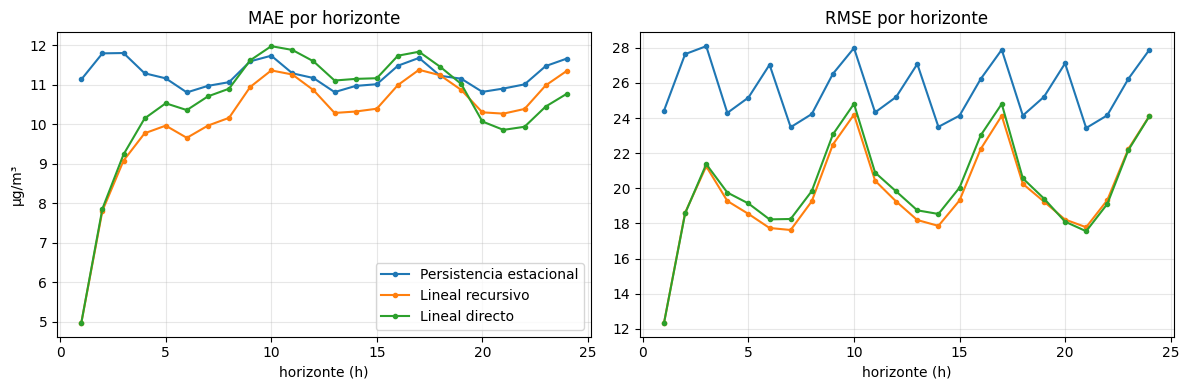

In [6]:
mae_h  = pd.DataFrame({c: (C[c] - C["real"]).abs().groupby(C["h"]).mean() for c in cols})
rmse_h = pd.DataFrame({c: np.sqrt(((C[c] - C["real"])**2).groupby(C["h"]).mean()) for c in cols})

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
mae_h.plot(ax=ax[0], marker="o", ms=3, title="MAE por horizonte"); ax[0].set_ylabel("µg/m³")
rmse_h.plot(ax=ax[1], marker="o", ms=3, title="RMSE por horizonte", legend=False)
for a in ax: a.set_xlabel("horizonte (h)"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Interpretación

- **Global:** los dos modelos lineales superan a la persistencia estacional en MAE (10,19 y 10,51 contra 11,25 µg/m³). La diferencia es mayor en RMSE (19,9 y 20,3 contra 25,7). La mejora es modesta en MAE, pero clara en RMSE, es decir, en los errores grandes. La estrategia recursiva queda apenas por debajo de la directa (0,3 µg/m³ en MAE), una diferencia pequeña que no alcanza para elegir una de las dos.
- **Por horizonte:** la ventaja de los modelos lineales se concentra en las primeras horas. En t+1 el MAE es ~5 contra ~11 de la persistencia, porque el modelo aprovecha el valor inmediatamente anterior. Esa ventaja se reduce rápidamente y, desde t+8 aproximadamente, el MAE queda cerca del de la persistencia. En horizontes largos (t+20 a t+24) la estrategia directa es la que se mantiene algo por debajo. Esto indica que el historial reciente informa bien a corto plazo, pero poco más allá de unas pocas horas.
- **RMSE:** los modelos lineales quedan por debajo de la persistencia en todos los horizontes. El RMSE presenta oscilaciones entre horizontes (picos en t+3, t+10, t+17, por ejemplo). Es probable que se deban a pocos episodios extremos combinados con `fold_stride=7`, y no a un efecto real del horizonte. Habría que verificarlo antes de interpretarlas.
- **Casos comparados:** las métricas se calcularon sobre 27.216 casos comunes (90,7 % de las predicciones), los mismos para los tres modelos.
- **Implicancia:** con solo el historial de PM2,5 hay una mejora real, pero acotada respecto a la persistencia, lo que es coherente con la literatura revisada (Asklany et al., 2025). Estos resultados son el punto de partida para comparar rezagos, familias de modelos y la incorporación de meteorología.